# Aperçu des résultats du 10 km (quiz P4)

Fichier CSV en ligne contenant les résultats de 340 coureurs classés à l'arrivée d'un 10 km.
Chaque ligne décrit un coureur : sa position à l'arrivée, son sexe, son temps (heures:minutes:secondes), son département de résidence, son temps en secondes et son âge.

Cet aperçu montre : le chargement du fichier, les dimensions du tableau, un extrait, le dictionnaire de données, les types des colonnes, les valeurs manquantes, les statistiques numériques et quelques répartitions simples.

In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

URL = "https://s3.eu-west-1.amazonaws.com/course.oc-static.com/courses/7410486/course+-+Quiz+P4+(1).csv"
RESOURCES_DIR = Path("resources")
if not RESOURCES_DIR.exists():  # notebook ouvert depuis la racine du projet
    RESOURCES_DIR = Path("notebooks") / "resources"

# un CSV distant se télécharge avec requests, jamais avec read_csv(url)
fichier_csv = RESOURCES_DIR / "quiz_p4_10km.csv"
reponse = requests.get(URL, timeout=60)
reponse.raise_for_status()  # lève une erreur si le téléchargement échoue
fichier_csv.write_bytes(reponse.content)

df = pd.read_csv(fichier_csv)

## Dimensions du tableau

In [2]:
nb_lignes = len(df)
nb_colonnes = len(df.columns)

In [3]:
print(f"Le tableau contient {nb_lignes} coureurs (lignes) et {nb_colonnes} colonnes.")

Le tableau contient 340 coureurs (lignes) et 6 colonnes.


## Extrait : les 5 premiers coureurs

In [4]:
df.head()

,Position,Sexe,Temps,Dept,Temps_secondes,Age
0,1,M,00:32:23,76,1643543,40
1,2,M,00:32:40,27,1643560,34
2,3,M,00:33:15,76,1643595,44
3,4,M,00:33:23,76,1643603,46
4,5,M,00:33:29,76,1643609,26


## Dictionnaire de données

In [5]:
definitions = {
    "Position": "Classement à l'arrivée, de 1 (premier arrivé) à 340 (dernier arrivé).",
    "Sexe": "Sexe du coureur : M (homme) ou F (femme).",
    "Temps": "Temps réalisé au format heures:minutes:secondes (ex : 00:32:23 = 32 min 23 s).",
    "Dept": "Numéro du département de résidence du coureur.",
    "Temps_secondes": "Temps réalisé, exprimé en secondes.",
    "Age": "Âge du coureur en années.",
}
dictionnaire = pd.DataFrame({
    "Colonne": list(definitions),
    "Définition": list(definitions.values()),
})

In [6]:
dictionnaire

,Colonne,Définition
0,Position,"Classement à l'arrivée, de 1 (premier arrivé) ..."
1,Sexe,Sexe du coureur : M (homme) ou F (femme).
2,Temps,Temps réalisé au format heures:minutes:seconde...
3,Dept,Numéro du département de résidence du coureur.
4,Temps_secondes,"Temps réalisé, exprimé en secondes."
5,Age,Âge du coureur en années.


## Types des colonnes

In [7]:
types = df.dtypes

In [8]:
pd.DataFrame({"Colonne": types.index, "Type": [str(t) for t in types.values]})

,Colonne,Type
0,Position,int64
1,Sexe,str
2,Temps,str
3,Dept,int64
4,Temps_secondes,int64
5,Age,int64


## Valeurs manquantes

In [9]:
manquants = df.isna().sum()
total_manquants = manquants.sum()

In [10]:
print(f"Valeurs manquantes au total : {total_manquants}")
manquants.to_frame("Manquantes")

Valeurs manquantes au total : 0


,Manquantes
Position,0
Sexe,0
Temps,0
Dept,0
Temps_secondes,0
Age,0


## Statistiques des colonnes numériques

In [11]:
stats = df.describe()

In [12]:
stats

,Position,Dept,Temps_secondes,Age
count,340.000000,340.000000,3.400000e+02,340.000000
mean,170.500000,56.991176,1.644553e+06,41.950000
std,98.293777,25.059279,5.145263e+02,12.092094
min,1.000000,14.000000,1.643543e+06,18.000000
25%,85.750000,27.000000,1.644200e+06,34.000000
50%,170.500000,76.000000,1.644536e+06,42.000000
75%,255.250000,76.000000,1.644906e+06,50.000000
max,340.000000,78.000000,1.645831e+06,74.000000


## Répartitions simples

In [13]:
repartition_sexe = df["Sexe"].value_counts()
departements = sorted(int(d) for d in df["Dept"].unique())
age_min = df["Age"].min()
age_max = df["Age"].max()

In [14]:
print("Répartition par sexe :")
print(repartition_sexe)
print()
print(f"Départements présents ({len(departements)}) : {departements}")
print(f"Âge des coureurs : de {age_min} à {age_max} ans")

Répartition par sexe :
Sexe
M    248
F     92
Name: count, dtype: int64

Départements présents (4) : [14, 27, 76, 78]
Âge des coureurs : de 18 à 74 ans


## Corrélation entre la position et l'âge

Deux outils simples pour mesurer le lien entre deux colonnes numériques (`Position` et `Age`) :

1. **le nuage de points** : chaque coureur est un point (âge en abscisse, position en ordonnée). Si les points montent ou descendent ensemble, il y a un lien visible ;
2. **le coefficient de corrélation** : un nombre entre -1 et 1. Proche de 1, la position augmente quand l'âge augmente ; proche de -1, c'est l'inverse ; proche de 0, il n'y a pas de lien linéaire.

Rappel : la position 1 est le premier arrivé, donc une position plus grande = un coureur plus lent.

In [15]:
correlation = df["Position"].corr(df["Age"])

In [16]:
print(f"Coefficient de corrélation entre la position et l'âge : {correlation:.3f}")

Coefficient de corrélation entre la position et l'âge : 0.106


### Nuage de points : position en fonction de l'âge

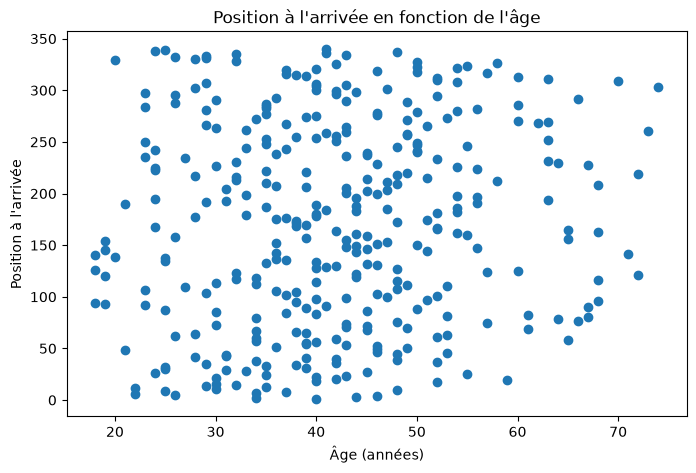

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["Position"])
plt.xlabel("Âge (années)")
plt.ylabel("Position à l'arrivée")
plt.title("Position à l'arrivée en fonction de l'âge")
plt.show()

## Discrétisation de l'âge en tranches de 10 ans

Discrétiser, c'est transformer une colonne continue (l'âge) en catégories. Ici, `pd.cut` découpe l'âge en intervalles de 10 ans : 18-27, 28-37, etc. On stocke le résultat dans une nouvelle colonne `Tranche_age`.

`right=False` signifie que chaque tranche contient son début mais pas sa fin : [18, 28[ = les âges 18 à 27 ans.

In [18]:
df["Tranche_age"] = pd.cut(
    df["Age"],
    bins=range(18, 80, 10),
    right=False,
    labels=["18-27", "28-37", "38-47", "48-57", "58-67", "68-77"],
)
effectifs = df["Tranche_age"].value_counts().sort_index()

In [19]:
df[["Age", "Tranche_age"]].head(10)

,Age,Tranche_age
0,40,38-47
1,34,28-37
2,44,38-47
3,46,38-47
4,26,18-27
5,22,18-27
6,34,28-37
7,37,28-37
8,25,18-27
9,48,48-57


In [20]:
effectifs.to_frame("Nombre de coureurs")

,Nombre de coureurs
Tranche_age,
18-27,41
28-37,83
38-47,110
48-57,71
58-67,25
68-77,10


### Position moyenne par tranche d'âge

Si l'âge jouait sur le classement, la position moyenne changerait d'une tranche à l'autre. On calcule donc la moyenne de `Position` dans chaque tranche avec `groupby`.

In [21]:
position_moyenne = df.groupby("Tranche_age")["Position"].mean().round(1)

In [22]:
position_moyenne.to_frame("Position moyenne")

,Position moyenne
Tranche_age,
18-27,159.3
28-37,162.9
38-47,164.5
48-57,186.1
58-67,187.3
68-77,193.7


### Les bords de tranches changent-ils le résultat ?

Non. Testons avec des tranches alignées sur les dizaines (10-20, 20-30, ...) puis avec le découpage du quiz (- 30, 30-40, 40-50, 50-60, 60+) : les positions moyennes restent dans la même plage, sans tendance nette. Et le coefficient r = 0,106 ne dépend pas des tranches du tout, puisqu'il se calcule sur l'âge brut.

In [23]:
tranche_dizaine = pd.cut(df["Age"], bins=range(10, 81, 10))  # 10-20, 20-30, ...
moyennes_dizaines = df.groupby(tranche_dizaine, observed=True)["Position"].mean().round(1)

def cat_quiz(age):
    if age <= 30:
        return "- 30"
    if age <= 40:
        return "30-40"
    if age <= 50:
        return "40-50"
    if age <= 60:
        return "50-60"
    return "60+"

tranche_quiz = df["Age"].map(cat_quiz)
moyennes_quiz = df.groupby(tranche_quiz, observed=True)["Position"].mean().round(1)

In [24]:
print("Positions moyennes avec les tranches 10-20, 20-30, ... :")
print(moyennes_dizaines)
print()
print("Positions moyennes avec les tranches du quiz (- 30, 30-40, ...) :")
print(moyennes_quiz)
print()
print(f"r Age/Position, calculé sur l'âge brut (indépendant des tranches) : {correlation:.3f}")

Positions moyennes avec les tranches 10-20, 20-30, ... :
Age
(10, 20]    148.9
(20, 30]    165.8
(30, 40]    157.6
(40, 50]    175.8
(50, 60]    189.0
(60, 70]    174.9
(70, 80]    209.0
Name: Position, dtype: float64

Positions moyennes avec les tranches du quiz (- 30, 30-40, ...) :
Age
- 30     163.5
30-40    157.6
40-50    175.8
50-60    189.0
60+      181.0
Name: Position, dtype: float64

r Age/Position, calculé sur l'âge brut (indépendant des tranches) : 0.106


## Conclusion sur la corrélation entre l'âge et la position

In [25]:
print(f"Coefficient de corrélation âge / position : {correlation:.3f}")
print(f"Position moyenne par tranche d'âge : de {position_moyenne.min():.1f} à {position_moyenne.max():.1f}")
print(f"Effectifs des deux dernières tranches : {effectifs.iloc[-2]} et {effectifs.iloc[-1]} coureurs")

Coefficient de corrélation âge / position : 0.106
Position moyenne par tranche d'âge : de 159.3 à 193.7
Effectifs des deux dernières tranches : 25 et 10 coureurs


### Conclusion : pas de corrélation apparente, et pourquoi

- le coefficient vaut **r = 0,106**, quasiment 0 : il n'y a **pas de corrélation apparente** entre l'âge et la position (formulation attendue) ;
- le nuage de points est dispersé, sans direction nette ;
- les positions moyennes par tranche restent dans une plage étroite (de 159,3 à 193,7), et ce quelle que soit la façon de couper les tranches (voir cellule précédente) ;
- une corrélation, même forte, ne prouverait jamais un lien de cause à effet.

**Conclusion :** dans cet échantillon de 340 coureurs, on n'observe pas de corrélation apparente entre l'âge et la position à l'arrivée (r = 0,106).

## Régression linéaire : Position en fonction de l'âge

Une régression linéaire cherche la droite qui approche le mieux le nuage de points :

**Position = pente × Age + ordonnée à l'origine**

- la **pente** dit de combien la position augmente en moyenne quand l'âge augmente de 1 an ;
- l'**ordonnée à l'origine** est la position prédite pour un âge de 0 an (valeur théorique ici) ;
- le **R²** est la part de la variance des positions expliquée par le modèle. En régression simple (une seule variable explicative), R² = r², le carré du coefficient de corrélation.

`np.polyfit(x, y, 1)` calcule directement la pente et l'ordonnée à l'origine de la droite des moindres carrés. On trace ensuite la droite sur le graphique pour la visualiser.

In [26]:
pente, ordonnee_origine = np.polyfit(df["Age"], df["Position"], 1)
r2 = correlation ** 2  # en régression simple, R² = r²
position_predite = pente * df["Age"] + ordonnee_origine
residus = df["Position"] - position_predite  # écart entre réel et prédit

In [27]:
print(f"Modèle : Position = {pente:.3f} x Age + {ordonnee_origine:.1f}")
print(f"Pente : {pente:.3f} (chaque année de plus = {pente:.3f} position de plus en moyenne)")
print(f"Ordonnée à l'origine : {ordonnee_origine:.1f}")
print(f"R² = r² = {r2:.4f}, soit {r2 * 100:.1f} % de la variance expliquée")
print(f"Écarts à la droite (résidus) : de {residus.min():.0f} à {residus.max():.0f} places")

Modèle : Position = 0.862 x Age + 134.3
Pente : 0.862 (chaque année de plus = 0.862 position de plus en moyenne)
Ordonnée à l'origine : 134.3
R² = r² = 0.0112, soit 1.1 % de la variance expliquée
Écarts à la droite (résidus) : de -170 à 183 places


### Graphique 1 : le nuage de points et la droite de régression

Chaque point gris est un coureur (son âge, sa position réelle). La droite rouge est le modèle : c'est la droite qui passe « au milieu » du nuage, au sens des moindres carrés. Son équation est écrite dans le titre du graphique.

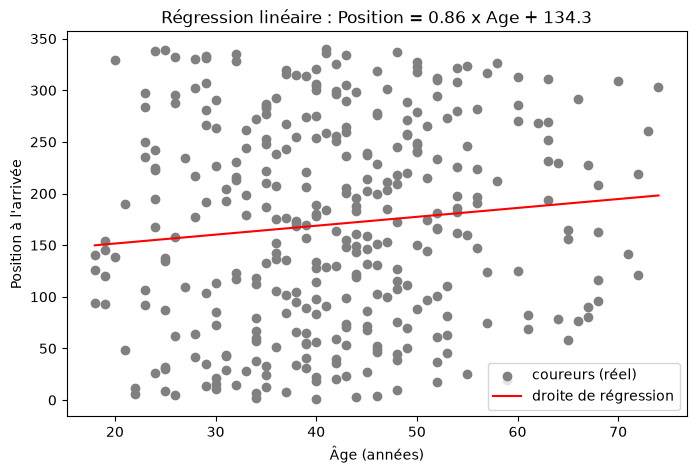

In [28]:
ages = np.sort(df["Age"].unique())  # âges triés pour tracer une droite lisse

plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["Position"], color="grey", label="coureurs (réel)")
plt.plot(ages, pente * ages + ordonnee_origine, color="red", label="droite de régression")
plt.xlabel("Âge (années)")
plt.ylabel("Position à l'arrivée")
plt.title(f"Régression linéaire : Position = {pente:.2f} x Age + {ordonnee_origine:.1f}")
plt.legend()
plt.show()

### Graphique 2 : les résidus, c'est-à-dire de combien le modèle se trompe

Pour chaque coureur, le **résidu** = position réelle - position prédite par la droite. C'est la distance verticale entre le point et la droite rouge du graphique 1.

- si le modèle était parfait, tous les résidus seraient 0 (tous les points sur la droite) ;
- ici, les résidus vont de -170 à +183 places (sortie de la cellule précédente) : la droite se trompe beaucoup ;
- c'est exactement ce que mesure le R² : la part de la dispersion des points que la droite arrive à expliquer. Avec R² = 1,1 %, la droite n'explique presque rien.

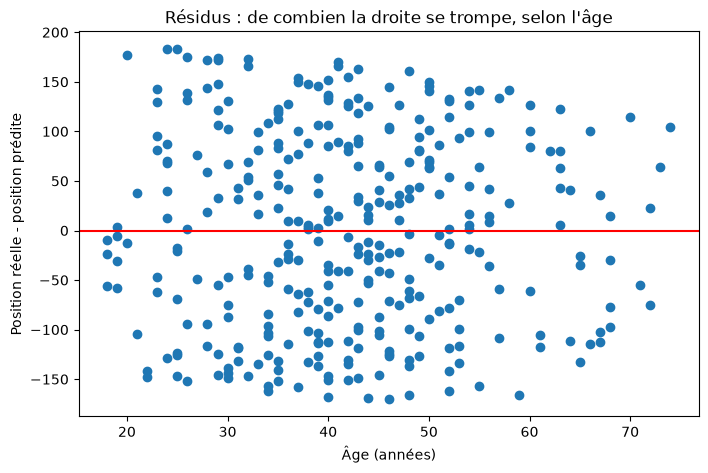

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], residus)
plt.axhline(0, color="red")  # la droite du modèle = résidu nul
plt.xlabel("Âge (années)")
plt.ylabel("Position réelle - position prédite")
plt.title("Résidus : de combien la droite se trompe, selon l'âge")
plt.show()

### Interprétation simple

- la pente est positive mais faible (0,862) : vieillir d'un an correspond en moyenne à moins d'une place de plus ;
- sur le graphique 1, la droite rouge est presque horizontale par rapport à l'échelle des positions (1 à 340) : l'âge fait varier la prédiction de seulement ~50 places entre 18 et 74 ans ;
- sur le graphique 2, les points sont très éloignés de la ligne rouge (résidu = 0) : le modèle se trompe souvent de plus de 100 places ;
- le R² vaut environ **0,011**, soit **1,1 %** : le modèle linéaire n'explique qu'environ 1 % de la variation des positions.

**En résumé :** connaître l'âge d'un coureur ne permet quasiment pas de prédire sa position à l'arrivée.

## ANOVA : y a-t-il un lien entre le sexe et le temps ?

Ici, `Sexe` est une variable **qualitative** (deux groupes : M et F) et `Temps_secondes` est une variable **quantitative**. Pour comparer une moyenne entre plusieurs groupes, on utilise une **ANOVA** (analyse de la variance).

L'ANOVA décompose la variance totale du temps en deux parties :

- **variance entre les groupes** (SS entre) : les moyennes de M et F diffèrent-elles ?
- **variance dans les groupes** (SS dans) : la dispersion à l'intérieur de chaque groupe.

Le **η² (eta carré)** = SS entre / SS total. C'est un nombre entre 0 et 1, comme un R² : il dit **quelle part de la variation du temps est expliquée par le sexe**. 0 = le sexe n'explique rien, 1 = le sexe explique tout.

In [30]:
y = df["Temps_secondes"].to_numpy(dtype=float)
groupes = [g["Temps_secondes"].to_numpy(dtype=float) for _, g in df.groupby("Sexe")]
moyennes_sexe = df.groupby("Sexe")["Temps_secondes"].mean()

grand_moyenne = y.mean()
ss_total = ((y - grand_moyenne) ** 2).sum()
ss_entre = sum(len(g) * (g.mean() - grand_moyenne) ** 2 for g in groupes)
ss_dans = ss_total - ss_entre

eta2 = ss_entre / ss_total
k = len(groupes)  # nombre de groupes (2 : M et F)
n = len(y)
F = (ss_entre / (k - 1)) / (ss_dans / (n - k))  # statistique F de l'ANOVA

In [31]:
print("Temps moyen par sexe (secondes) :")
print(moyennes_sexe.round(1))
print()
print(f"Différence entre les deux moyennes : {moyennes_sexe.max() - moyennes_sexe.min():.1f} secondes")
print(f"η² (eta carré) = {eta2:.4f}, soit {eta2 * 100:.1f} % de la variance de Temps_secondes expliquée par le sexe")
print(f"Statistique F de l'ANOVA = {F:.1f}")

Temps moyen par sexe (secondes) :
Sexe
F    1644934.1
M    1644411.8
Name: Temps_secondes, dtype: float64

Différence entre les deux moyennes : 522.3 secondes
η² (eta carré) = 0.2040, soit 20.4 % de la variance de Temps_secondes expliquée par le sexe
Statistique F de l'ANOVA = 86.6


### Graphique : répartition du temps selon le sexe

Une boîte à moustaches résume chaque groupe : la ligne au milieu de la boîte est la médiane, la boîte va du 1er au 3e quartile. Si les deux boîtes se chevauchent beaucoup, les deux groupes ont des temps proches.

<Figure size 600x500 with 0 Axes>

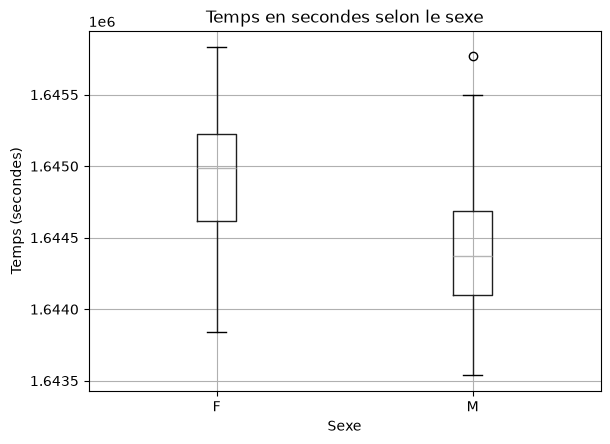

In [32]:
plt.figure(figsize=(6, 5))
df.boxplot(column="Temps_secondes", by="Sexe")
plt.suptitle("")  # enlève le titre automatique ajouté par pandas
plt.title("Temps en secondes selon le sexe")
plt.xlabel("Sexe")
plt.ylabel("Temps (secondes)")
plt.show()

### Que signifie le η² obtenu ?

**η² = 0,204**, soit environ **20 %** (valeur affichée par la cellule de code ci-dessus).

Cela signifie que **le sexe explique environ 20 % de la variance de `Temps_secondes`** : sur toutes les différences de temps entre coureurs, environ un cinquième vient du fait d'être un homme ou une femme. Les 80 % restants viennent d'autres facteurs (entraînement, forme du jour, etc.).

- η² proche de 0 : le sexe n'a presque aucun lien avec le temps ;
- η² proche de 1 : le sexe expliquerait presque tout ;
- ici, η² = 0,204 : **lien modéré**. La statistique F = 86,6 est très grande, ce qui confirme que la différence de temps moyen entre M et F (environ 522 secondes, soit ~8 min 40 s) n'est pas due au hasard.

Comme toujours, cela montre une association, pas une cause à effet.

## Hors sujet : lire une heatmap et en tirer des conclusions

Exemple tiré d'une heatmap 3×3 : deux variables qualitatives, la première avec les catégories A, B, C et la seconde avec les catégories 0, 1, 2. Les valeurs des cellules (en notation scientifique, ex : 2.9e+02 = 290) forment le **tableau de contingence**.

Ce que la heatmap permet de conclure, et ce qu'elle ne permet pas :

- **elle ne suffit pas en elle-même** pour affirmer une corrélation : il faudrait un test statistique (chi²) ;
- visuellement, on peut repérer quelles catégories semblent contribuer le plus (valeurs normalisées les plus hautes).

On montre ci-dessous les deux lectures : le test du chi² (pour savoir s'il y a un lien) et les contributions (pour savoir quelles catégories portent le lien).

In [33]:
table = pd.DataFrame(
    [[290, 290, 620],
     [600, 220, 980],
     [240, 580, 160]],
    index=["A", "B", "C"],
    columns=[0, 1, 2],
)

In [34]:
table

,0,1,2
A,290,290,620
B,600,220,980
C,240,580,160


### Le test du chi² d'indépendance (ce qu'il faudrait faire pour conclure)

Hypothèse nulle : les deux variables sont indépendantes (aucun lien).

- **effectif attendu** d'une cellule si indépendance : E = (total ligne × total colonne) / total général ;
- **chi²** = Σ (observé − attendu)² / attendu, sommé sur toutes les cellules ;
- **degrés de liberté** = (nb lignes − 1) × (nb colonnes − 1) = 2 × 2 = 4 ;
- si chi² dépasse la valeur critique (9,49 à 4 ddl et 5 %), on rejette l'indépendance : il y a un lien significatif.

Attention : ce test se fait sur le tableau de données, pas sur le dessin de la heatmap.

In [35]:
valeurs = table.to_numpy(dtype=float)
n = valeurs.sum()
attendus = np.outer(table.sum(axis=1), table.sum(axis=0)) / n  # E si indépendance
contributions = (valeurs - attendus) ** 2 / attendus  # contribution de chaque cellule au chi²
chi2 = contributions.sum()
ddl = (table.shape[0] - 1) * (table.shape[1] - 1)
seuil_5pct = 9.49  # valeur critique du chi² à 4 ddl, seuil de 5 %

In [36]:
print(f"n total = {int(n)}")
print(f"chi² = {chi2:.2f} | ddl = {ddl} | valeur critique à 5 % = {seuil_5pct}")
print(f"chi² > seuil : {chi2 > seuil_5pct} → si on fait le test, le lien est significatif")

n total = 3980
chi² = 775.78 | ddl = 4 | valeur critique à 5 % = 9.49
chi² > seuil : True → si on fait le test, le lien est significatif


### La taille d'effet : le V de Cramér

Le chi² dépend de la taille de l'échantillon. Le **V de Cramér** corrige ça :

**V = √( chi² / (n × min(nb lignes − 1, nb colonnes − 1)) )**, entre 0 (aucun lien) et 1 (lien parfait).

In [37]:
v_cramer = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

In [38]:
print(f"V de Cramér = {v_cramer:.3f} (lien modéré à fort si on fait le test)")

V de Cramér = 0.312 (lien modéré à fort si on fait le test)


### Quelles catégories portent le lien ? Les contributions cellule par cellule

Chaque cellule contribue au chi² par **(observé − attendu)² / attendu**. Une contribution élevée = une cellule qui s'écarte beaucoup de l'indépendance. En sommant par ligne et par colonne, on voit quelles catégories « tirent » le lien.

In [39]:
contrib = pd.DataFrame(contributions, index=table.index, columns=table.columns)
part_lignes = contrib.sum(axis=1) / chi2 * 100  # % du chi² par catégorie de la 1re variable
part_colonnes = contrib.sum(axis=0) / chi2 * 100  # % du chi² par catégorie de la 2e variable

In [40]:
print("Contributions au chi², cellule par cellule :")
display(contrib.round(1))
print("Part du chi² par ligne (catégories A, B, C) :")
print(part_lignes.round(1))
print()
print("Part du chi² par colonne (catégories 0, 1, 2) :")
print(part_colonnes.round(1))

Contributions au chi², cellule par cellule :


,0,1,2
A,7.5,4.5,15.0
B,15.5,151.1,42.5
C,5.3,361.8,172.4


Part du chi² par ligne (catégories A, B, C) :
A     3.5
B    27.0
C    69.5
dtype: float64

Part du chi² par colonne (catégories 0, 1, 2) :
0     3.6
1    66.7
2    29.7
dtype: float64


### La heatmap : utile pour visualiser, mais pas pour conclure

Deux façons de dessiner la même heatmap :

- **effectifs bruts** : la couleur = la vraie valeur de la cellule ;
- **proportions normalisées** (ici par ligne) : la couleur = une proportion, avec les effectifs bruts en annotation. C'est ce mode qui produit des heatmaps où une cellule à 980 peut paraître « foncée » et une à 580 « claire » : le visuel change selon la normalisation.

Moralité : pour conclure, on fait le test du chi² sur le tableau, on ne se fie pas au dessin.

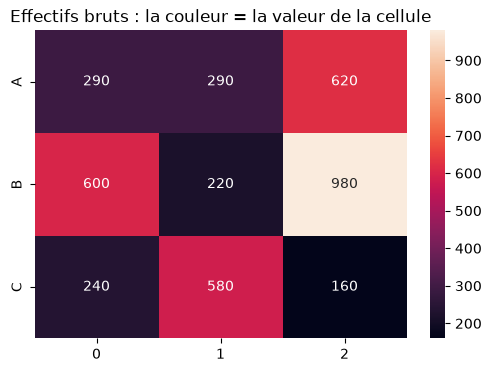

In [41]:
plt.figure(figsize=(6, 4))
sns.heatmap(table, annot=True, fmt="d", cmap="rocket")
plt.title("Effectifs bruts : la couleur = la valeur de la cellule")
plt.show()

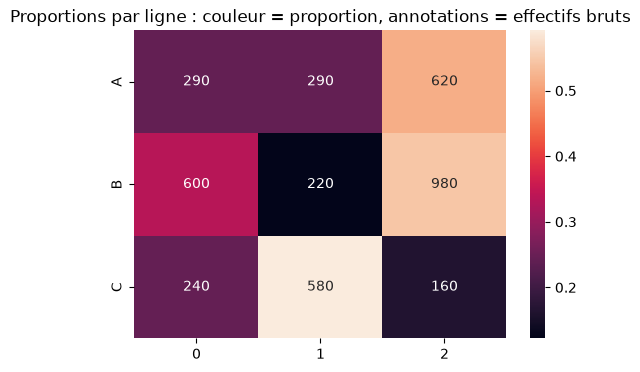

In [42]:
table_norm = table.div(table.sum(axis=1), axis=0)  # proportions par ligne

plt.figure(figsize=(6, 4))
sns.heatmap(table_norm, annot=table, fmt="d", cmap="rocket")
plt.title("Proportions par ligne : couleur = proportion, annotations = effectifs bruts")
plt.show()

### Conclusions (réponses attendues au quiz)

- ❌ **« Il y a clairement une corrélation entre les deux variables »** : faux tel quel. La heatmap seule ne permet pas d'affirmer une corrélation claire : il faudrait le test du chi². De plus, entre deux variables **qualitatives**, on parle d'association, pas de corrélation (mot réservé aux variables quantitatives).
- ❌ **« La catégorie A contribue le plus »** : faux. Les contributions au chi² donnent A = 3,5 % du total (la plus faible), contre C = 69,5 %.
- ✅ **« La catégorie 1 de la seconde variable contribue de façon importante »** : oui, 66,7 % du chi² (et sur la heatmap normalisée, ses valeurs ~0,5 sont les plus hautes).
- ✅ **« La heatmap ne suffit pas en elle-même pour conclure »** : oui, c'est le test du chi² qui conclut, pas le dessin.

**Réponses attendues : les affirmations 3 et 4.** (Pour info, le chi² calculé ci-dessus vaut 775,78 > 9,49 : si on fait le test sur le tableau, le lien est significatif. Mais ce n'est pas ce que la heatmap seule permet d'affirmer.)